<a href="https://colab.research.google.com/github/cherrynovagh/cherrynova/blob/main/hw05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Question 1

**Given:**

$$H_1: \mathbf{w}^\top \mathbf{x} = 52 \qquad H_2: \mathbf{w}^\top \mathbf{x} = 64$$

Both hyperplanes have the same normal vector $\mathbf{w}$, so they are **parallel**. Only their constant terms differ.

Let $\mathbf{x}_0$ be any point on $H_1$, so $\mathbf{w}^\top \mathbf{x}_0 = 52$.

The shortest path between two parallel hyperplanes runs along the unit normal direction $\frac{\mathbf{w}}{\|\mathbf{w}\|}$. Move a distance $d$ from $\mathbf{x}_0$ in that direction to reach $H_2$:

$$\mathbf{w}^\top\left(\mathbf{x}_0 + d\,\frac{\mathbf{w}}{\|\mathbf{w}\|}\right) = 64$$

$$\mathbf{w}^\top \mathbf{x}_0 + d\,\frac{\mathbf{w}^\top \mathbf{w}}{\|\mathbf{w}\|} = 64$$

Since $\mathbf{w}^\top \mathbf{w} = \|\mathbf{w}\|^2$:

$$52 + d\,\|\mathbf{w}\| = 64$$

$$d = \frac{64 - 52}{\|\mathbf{w}\|} = \frac{12}{\|\mathbf{w}\|}$$

**General result:** the distance between $\mathbf{w}^\top \mathbf{x} = b_1$ and $\mathbf{w}^\top \mathbf{x} = b_2$ is $\dfrac{|b_1 - b_2|}{\|\mathbf{w}\|}$.

Because $\mathbf{w}$ is unknown, the distance is expressed in terms of its norm $\|\mathbf{w}\|$.

Therefore, the distance is $d = \dfrac{12}{\|\mathbf{w}\|}$.

## Question 2

To avoid overfitting, I would use a soft-margin SVM instead of a hard-margin SVM.

A hard-margin SVM forces every training point to be classified correctly, so it fits noise and outliers and ends up with a very narrow margin. A soft-margin SVM adds slack variables $\xi_i$ that allow some points to fall inside the margin or be misclassified, with a penalty controlled by the parameter $C$:

$$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \ \frac{1}{2}\|\mathbf{w}\|^2 + C \sum_{i=1}^{n} \xi_i$$

A smaller $C$ allows more errors and gives a wider margin, which generalizes better and reduces overfitting.

I would also choose $C$ (and $\gamma$ if using the RBF kernel) using cross-validation, since a large $\gamma$ can also cause overfitting.

## Question 3

**Data:** $(1,2), (2,1), (4,5), (5,4)$

**Initial centroids:** $C_1 = (1,1)$, $C_2 = (5,5)$

**Step 1: Assign each point to the nearest centroid** (Euclidean distance)

| Point| Distance to $C_1 = (1,1)$ | Distance to $C_2 = (5,5)$ | Cluster |
|---|---|---|---|
| $(1,2)$ | $\sqrt{0^2 + 1^2} = 1$ | $\sqrt{4^2 + 3^2} = 5$ | $C_1$ |
| $(2,1)$ | $\sqrt{1^2 + 0^2} = 1$ | $\sqrt{3^2 + 4^2} = 5$ | $C_1$ |
| $(4,5)$ | $\sqrt{3^2 + 4^2} = 5$ | $\sqrt{1^2 + 0^2} = 1$ | $C_2$ |
| $(5,4)$ | $\sqrt{4^2 + 3^2} = 5$ | $\sqrt{0^2 + 1^2} = 1$ | $C_2$ |

Cluster 1: $\{(1,2), (2,1)\}$  
Cluster 2: $\{(4,5), (5,4)\}$

**Step 2: Updating each centroid to the mean of its cluster**

$$C_1 = \left(\frac{1+2}{2}, \frac{2+1}{2}\right) = (1.5,\ 1.5)$$

$$C_2 = \left(\frac{4+5}{2}, \frac{5+4}{2}\right) = (4.5,\ 4.5)$$

**After one iteration, the new centroids are $C_1 = (1.5, 1.5)$ and $C_2 = (4.5, 4.5)$.**

## Question 4

Clustering groups similar data points together, so normal data ends up in well-defined clusters, while anomalies are points that don't fit well into any cluster. To detect them, I would first run a clustering algorithm like K-means, then calculate the distance of each point from its nearest cluster centroid. Points that are much farther away than most others (above a chosen threshold) would be flagged as anomalies. Another option is DBSCAN, which automatically labels points in low-density regions as noise, and those noise points can be treated as anomalies.

## Question 5

**Computing the weighted sum**

$$z = w_1x_1 + w_2x_2 + w_3x_3 + b$$

$$z = (0.6)(0.5) + (-0.3)(0.8) + (0.4)(0.2) + 0.1$$

$$z = 0.30 - 0.24 + 0.08 + 0.1 = 0.24$$

**Apply the Rectified Linear Unit (ReLU) activation**

$$a = f(z) = \max(0, z) = \max(0, 0.24) = 0.24$$

Since $z$ is positive, ReLU passes it through unchanged. **The output of the neuron is $a = 0.24$.**

## Question 6

**Data:** $\mathbf{x}^{(1)} = (2, 4),\ y^{(1)} = -1$ and $\mathbf{x}^{(2)} = (4, 5),\ y^{(2)} = 1$

**Weights:** $W^{[1]}_1 = [0.1, 0.3]$, $W^{[1]}_2 = [0.2, 0.4]$, $W^{[1]}_3 = [0.1, 0.5]$, $W^{[2]}_1 = [0.1, 0.2, 0.1]$, no bias, sigmoid activation, $\eta = 0.05$

### 6.1 Forward propagation: hidden layer

$z^{[1]}_j = W^{[1]}_{j1} x_1 + W^{[1]}_{j2} x_2$, and $a^{[1]}_j = \sigma(z^{[1]}_j)$

**Sample 1, $(2, 4)$:**
- $z^{[1]}_1 = 0.1(2) + 0.3(4) = 1.4$, so $a^{[1]}_1 = \sigma(1.4) = 0.8022$
- $z^{[1]}_2 = 0.2(2) + 0.4(4) = 2.0$, so $a^{[1]}_2 = \sigma(2.0) = 0.8808$
- $z^{[1]}_3 = 0.1(2) + 0.5(4) = 2.2$, so $a^{[1]}_3 = \sigma(2.2) = 0.9002$

**Sample 2, $(4, 5)$:**
- $z^{[1]}_1 = 0.1(4) + 0.3(5) = 1.9$, so $a^{[1]}_1 = \sigma(1.9) = 0.8699$
- $z^{[1]}_2 = 0.2(4) + 0.4(5) = 2.8$, so $a^{[1]}_2 = \sigma(2.8) = 0.9427$
- $z^{[1]}_3 = 0.1(4) + 0.5(5) = 2.9$, so $a^{[1]}_3 = \sigma(2.9) = 0.9478$

### 6.2 Forward propagation: output layer

$z^{[2]}_1 = 0.1\,a^{[1]}_1 + 0.2\,a^{[1]}_2 + 0.1\,a^{[1]}_3$, and $\hat{y} = a^{[2]}_1 = \sigma(z^{[2]}_1)$

**Sample 1:** $z^{[2]}_1 = 0.1(0.8022) + 0.2(0.8808) + 0.1(0.9002) = 0.3464$, so $a^{[2]}_1 = \sigma(0.3464) = 0.5857$

**Sample 2:** $z^{[2]}_1 = 0.1(0.8699) + 0.2(0.9427) + 0.1(0.9478) = 0.3703$, so $a^{[2]}_1 = \sigma(0.3703) = 0.5915$

### 6.3 Average loss

$$\mathcal{L} = -\frac{1}{2}\sum_{i=1}^{2}\left[y^{(i)}\log\hat{y}^{(i)} + (1-y^{(i)})\log(1-\hat{y}^{(i)})\right]$$

- Sample 1 ($y = -1$): $(-1)\log(0.5857) + (2)\log(0.4143) = 0.5349 - 1.7625 = -1.2276$
- Sample 2 ($y = 1$): $(1)\log(0.5915) + 0 = -0.5250$

$$\mathcal{L} = -\frac{1}{2}(-1.2276 - 0.5250) = \mathbf{0.8763}$$

### 6.4 Backward propagation: update $W^{[2]}_1$

By the chain rule, for each sample:

$$\frac{\partial \mathcal{L}}{\partial \hat{y}} \times \frac{\partial \hat{y}}{\partial z} = \left(-\frac{y}{\hat{y}} + \frac{1-y}{1-\hat{y}}\right)\hat{y}(1-\hat{y}) = \hat{y} - y$$

and $\frac{\partial z^{[2]}_1}{\partial W^{[2]}_1} = [a^{[1]}_1, a^{[1]}_2, a^{[1]}_3]$, so the gradient is $(\hat{y} - y)\,[a^{[1]}_1, a^{[1]}_2, a^{[1]}_3]$.

- Sample 1: $\hat{y} - y = 0.5857 - (-1) = 1.5857$, so the gradient is $1.5857 \times [0.8022, 0.8808, 0.9002] = [1.2721, 1.3967, 1.4276]$
- Sample 2: $\hat{y} - y = 0.5915 - 1 = -0.4085$, so the gradient is $-0.4085 \times [0.8699, 0.9427, 0.9478] = [-0.3553, -0.3851, -0.3872]$

**Average gradient:**

$$\nabla_{W^{[2]}_1}\mathcal{L} = \frac{1}{2}\left([1.2721, 1.3967, 1.4276] + [-0.3553, -0.3851, -0.3872]\right) = [0.4584, 0.5058, 0.5202]$$

**Update:**

$$W^{[2]}_1 = [0.1, 0.2, 0.1] - 0.05 \times [0.4584, 0.5058, 0.5202]$$

$${W^{[2]}_1 = [0.0771,\ 0.1747,\ 0.0740]}$$

## Question 7

Dropout is a regularization technique where, during training, a random fraction of neurons (for example, 20–50%) is temporarily "dropped" or set to zero at each training step. This means those neurons do not contribute to the forward pass or receive weight updates for that step, and a different random set of neurons is dropped each time.

Dropout is beneficial because it prevents the network from relying too heavily on any single neuron or on specific combinations of neurons. This forces the network to learn more robust, spread-out features, which reduces overfitting and helps the model generalize better to new data. It can also be thought of as training many smaller sub-networks at once and averaging them. Dropout is only applied during training; at test time, all neurons are used, and their outputs are scaled to account for the dropout used during training.

In [8]:
#Question 8
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Diabetes/diabetes.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [9]:
#Question 8
X = df.drop(columns="Outcome")
y = df["Outcome"]

X_scaled = StandardScaler().fit_transform(X)

In [10]:
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

print("Explained variance ratio:", pca2.explained_variance_ratio_.round(4))
print("Total variance explained:", pca2.explained_variance_ratio_.sum().round(4))

Explained variance ratio: [0.2618 0.2164]
Total variance explained: 0.4782


### 8.1 Answer
I standardized the features first, since PCA is sensitive to scale. With two principal components, PC1 explains about 26.2% of the variance and PC2 explains about 21.6%, for a total of about 47.8%. So two components keep less than half of the information in the original 8 features.

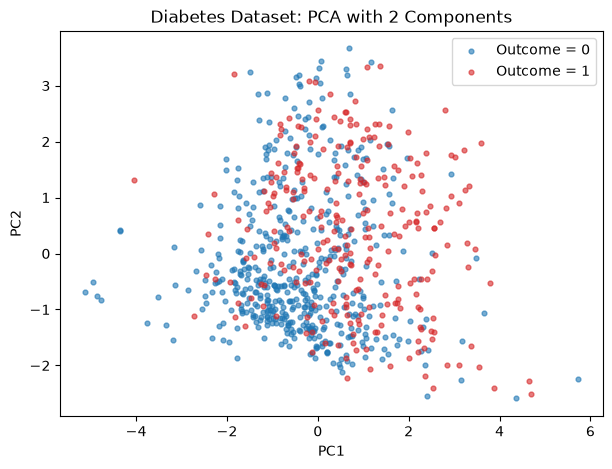

In [11]:
plt.figure(figsize=(7, 5))
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    plt.scatter(X_pca2[y == label, 0], X_pca2[y == label, 1],
                c=color, s=12, alpha=0.6, label=f"Outcome = {label}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Diabetes Dataset: PCA with 2 Components")
plt.legend()
plt.show()

### 8.2 Answer
In the 2D plot, the two classes overlap heavily. The diabetic points (Outcome = 1) tend to be shifted slightly toward the right along PC1, but most of them are mixed in with the non-diabetic points. So the two classes are not clearly distinguishable using only two principal components. This makes sense because the two components only capture about 48% of the variance, and PCA finds directions of maximum variance, not directions that best separate the classes.

In [12]:
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

for i, v in enumerate(pca3.explained_variance_ratio_, start=1):
    print(f"PC{i}: {v:.4f}")
print("Total variance explained:", pca3.explained_variance_ratio_.sum().round(4))

PC1: 0.2618
PC2: 0.2164
PC3: 0.1287
Total variance explained: 0.6069


### 8.3 Answer
With three components, PC1 explains about 26.2%, PC2 about 21.6%, and PC3 about 12.9% of the variance, for a total of about 60.7%. The third component adds about 12.9% more information, so the model now keeps more of the original data. However, PC3 contributes less than the first two components, so each additional component adds less than the one before it.

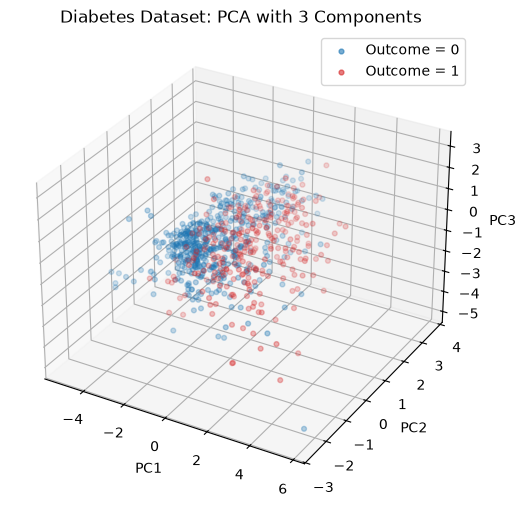

In [13]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    ax.scatter(X_pca3[y == label, 0], X_pca3[y == label, 1], X_pca3[y == label, 2],
               c=color, s=12, alpha=0.6, label=f"Outcome = {label}")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Diabetes Dataset: PCA with 3 Components")
ax.legend()
plt.show()

### 8.4 Answer
The 3D plot shows a little more spread between the classes than the 2D plot, since the third component adds extra information. The diabetic points still lean toward one side, but there is still a lot of overlap between the two classes. So the classes are only slightly more distinguishable in 3D, and they still cannot be cleanly separated. This suggests that the diabetes outcome depends on more complex patterns than the first few principal components can capture, and a supervised model would be needed to classify it well.

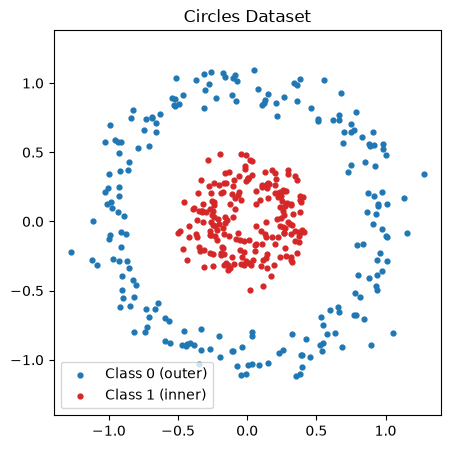

In [14]:
#Question 9
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

X, y = make_circles(n_samples=400, noise=0.1, factor=0.3, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

plt.figure(figsize=(5, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", s=12, label="Class 0 (outer)")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", s=12, label="Class 1 (inner)")
plt.title("Circles Dataset")
plt.legend()
plt.axis("equal")
plt.show()

In [15]:
def plot_boundary(model, X, y, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))
    xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolors="k", linewidths=0.2)
    ax.set_title(title)
    ax.set_aspect("equal")

### 9.1 Answer
The data forms two circles: one class is a small circle in the middle, and the other class is a ring around it. A linear SVM can only draw a straight line to separate the classes, and there is no straight line that can separate a circle from the ring surrounding it. Any line will cut through both classes, so a linear SVM will misclassify a large part of the data.

Linear SVM train accuracy: 0.661
Linear SVM test accuracy: 0.658


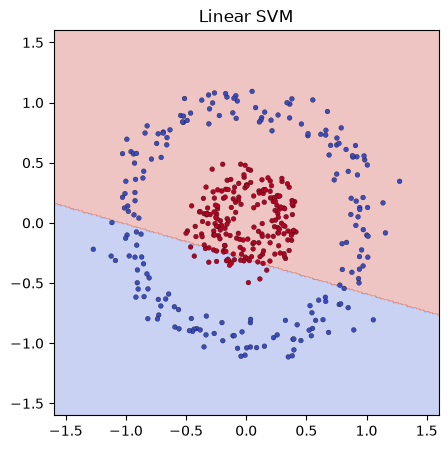

In [16]:
#Question 9.2
linear_svm = SVC(kernel="linear")
linear_svm.fit(X_train, y_train)

print("Linear SVM train accuracy:", round(linear_svm.score(X_train, y_train), 3))
print("Linear SVM test accuracy:", round(linear_svm.score(X_test, y_test), 3))
plot_boundary(linear_svm, X, y, "Linear SVM")
plt.show()

### 9.2 Answer
The linear SVM draws a straight line through the data and gets only about 66% test accuracy, which is close to guessing. This confirms the hypothesis from 9.1: a straight line cannot separate the inner circle from the outer ring.

RBF SVM (gamma=1.0) train accuracy: 1.0
RBF SVM (gamma=1.0) test accuracy: 1.0


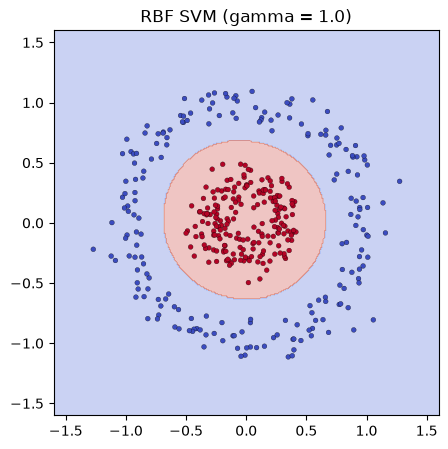

In [17]:
#Question 9.3
rbf_svm = SVC(kernel="rbf", gamma=1.0)
rbf_svm.fit(X_train, y_train)

print("RBF SVM (gamma=1.0) train accuracy:", round(rbf_svm.score(X_train, y_train), 3))
print("RBF SVM (gamma=1.0) test accuracy:", round(rbf_svm.score(X_test, y_test), 3))
plot_boundary(rbf_svm, X, y, "RBF SVM (gamma = 1.0)")
plt.show()

### 9.3 Answer
The RBF SVM reaches about 100% accuracy and draws a circular boundary around the inner class. The RBF kernel works by measuring how similar points are based on their distance from each other. This is like mapping the data into a higher-dimensional space where the two classes can be separated by a flat boundary. When that boundary is brought back to the original 2D space, it becomes a curve. The kernel does this without us having to transform the data ourselves.

gamma=0.1: train accuracy = 0.996, test accuracy = 1.000
gamma=10: train accuracy = 1.000, test accuracy = 1.000


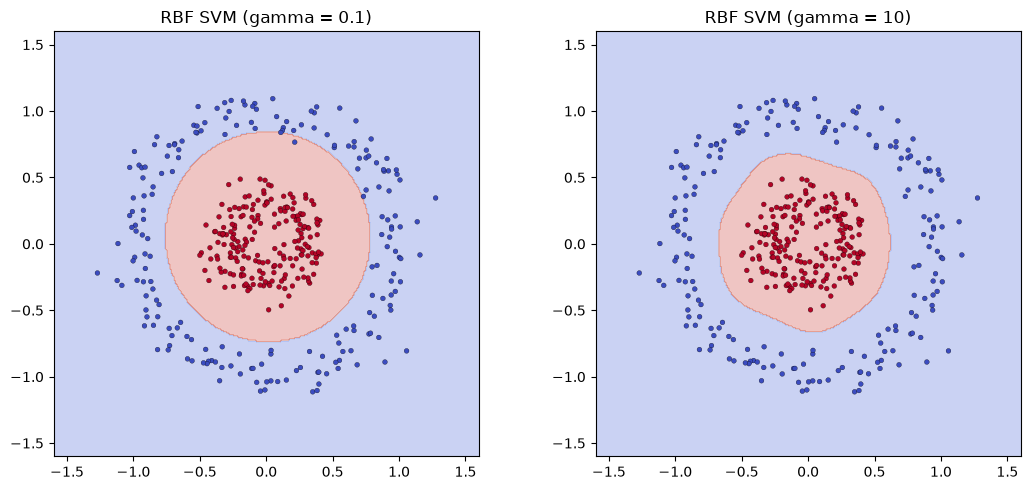

In [18]:
#Question 9.4
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, g in zip(axes, [0.1, 10]):
    model = SVC(kernel="rbf", gamma=g).fit(X_train, y_train)
    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)
    print(f"gamma={g}: train accuracy = {train_acc:.3f}, test accuracy = {test_acc:.3f}")
    plot_boundary(model, X, y, f"RBF SVM (gamma = {g})", ax=ax)
plt.tight_layout()
plt.show()

### 9.4 Answer
The gamma parameter controls how far each training point's influence reaches. With a small gamma (0.1), each point affects a large area, so the boundary is smooth and simple, and if gamma is too small the model can underfit by being too simple to capture the shape of the data. With a large gamma (10), each point only affects a small area, so the boundary follows the training points more closely, and if gamma is too large the model can overfit by fitting noise instead of the general pattern. In this case, all the models still got close to 100% accuracy because the circles are easy to separate, but you can see that gamma = 0.1 gives a looser, smoother boundary while gamma = 10 fits more tightly around the inner points.

In [19]:
#Question 10
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, v_measure_score,
                             silhouette_score, calinski_harabasz_score)

X, y_true = make_moons(n_samples=500, noise=0.2, random_state=42)

kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
labels = kmeans.fit_predict(X)

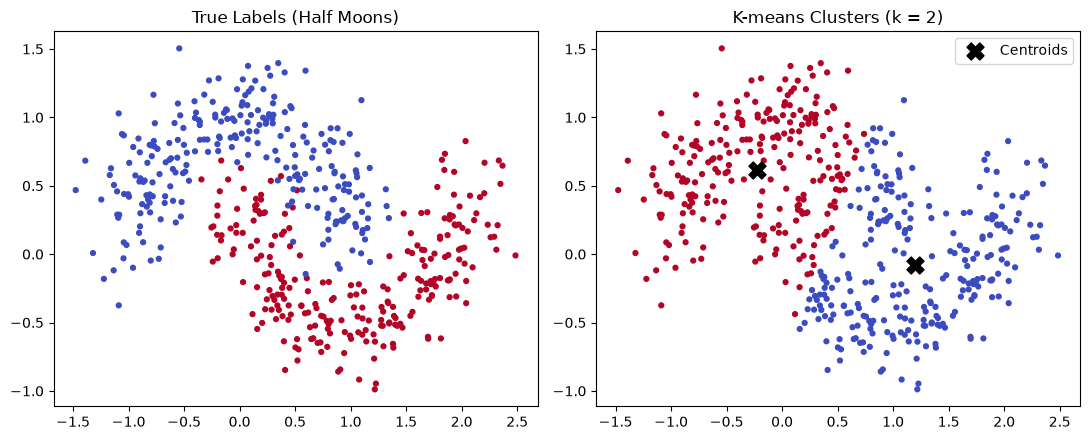

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(X[:, 0], X[:, 1], c=y_true, cmap="coolwarm", s=12)
axes[0].set_title("True Labels (Half Moons)")

axes[1].scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=12)
axes[1].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                c="black", marker="X", s=150, label="Centroids")
axes[1].set_title("K-means Clusters (k = 2)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [21]:
print(f"Adjusted Rand Index:     {adjusted_rand_score(y_true, labels):.3f}")
print(f"V-measure:               {v_measure_score(y_true, labels):.3f}")
print(f"Silhouette Score:        {silhouette_score(X, labels):.3f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz_score(X, labels):.1f}")

Adjusted Rand Index:     0.277
V-measure:               0.212
Silhouette Score:        0.469
Calinski-Harabasz Index: 664.1


### 10. Answer
I generated 500 half-moon samples with noise = 0.2 and applied K-means with 2 clusters. The Adjusted Rand Index (0.277) and V-measure (0.212) compare the clusters to the true labels, and both are low, which means K-means did not match the actual moon shapes well. The Silhouette Score (0.469) and Calinski-Harabasz Index (664.1) only look at how compact and separated the clusters are, so they look moderately good, because K-means did create two fairly compact groups. However, the plot shows that K-means split the data with roughly a straight line instead of following the curved moons. This happens because K-means assumes clusters are round and grouped around a centroid, so it does not work well for curved, non-convex shapes like half moons.

In [22]:
# Question 11
!pip install --upgrade cherrynova==0.6.0

In [23]:
import torch
import pandas as pd
from cherrynova.model.neuralnet import TorchNet

torch.manual_seed(42)

In [24]:
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Diabetes/diabetes.csv"
df = pd.read_csv(url)
X = df.drop(columns="Outcome")
y = df["Outcome"].values
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [25]:
model = TorchNet(input_dim=X.shape[1], output_dim=1)
print(model)

X_scaled = model.standardize(X)
print("Mean after scaling:", X_scaled.mean(axis=0).round(2))
print("Std after scaling:", X_scaled.std(axis=0).round(2))

TorchNet(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=4, bias=True)
    (1): ReLU()
    (2): Linear(in_features=4, out_features=3, bias=True)
    (3): ReLU()
    (4): Linear(in_features=3, out_features=1, bias=True)
  )
  (loss_fn): BCEWithLogitsLoss()
)
Mean after scaling: [ 0. -0. -0. -0.  0. -0.  0. -0.]
Std after scaling: [1. 1. 1. 1. 1. 1. 1. 1.]


In [26]:
losses = model.train_model(X_scaled, y, epochs=1000)

Epoch    1/1000  Loss: 0.7046
Epoch  100/1000  Loss: 0.4383
Epoch  200/1000  Loss: 0.4330
Epoch  300/1000  Loss: 0.4287
Epoch  400/1000  Loss: 0.4260
Epoch  500/1000  Loss: 0.4186
Epoch  600/1000  Loss: 0.4169
Epoch  700/1000  Loss: 0.4156
Epoch  800/1000  Loss: 0.4149
Epoch  900/1000  Loss: 0.4144
Epoch 1000/1000  Loss: 0.4138


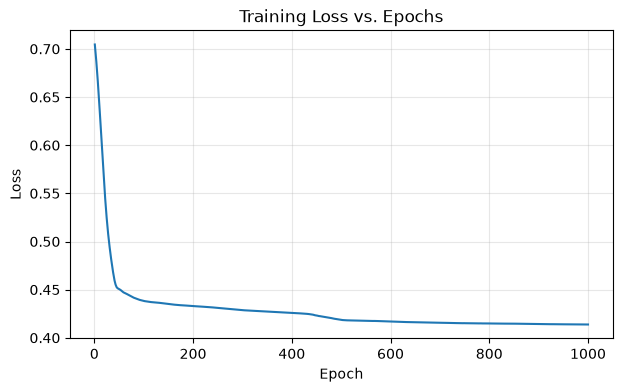

In [27]:
model.plot_loss()

In [28]:
model.save_onnx("torchnet.onnx")

[torch.onnx] Obtain model graph for `TorchNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `TorchNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Model saved to torchnet.onnx


'torchnet.onnx'

In [29]:
new_sample = pd.DataFrame([{
    "Pregnancies": 7, "Glucose": 149, "BloodPressure": 73, "SkinThickness": 94,
    "Insulin": 94, "BMI": 32, "DiabetesPedigreeFunction": 0.672, "Age": 45
}])

prediction, probability = model.predict_onnx(new_sample, "torchnet.onnx")
print(f"Predicted Outcome: {prediction[0]}  (probability of diabetes = {probability[0]:.3f})")

Predicted Outcome: 0  (probability of diabetes = 0.118)


Commit hash: https://github.com/cherrynovagh/cherrynova/commit/7ebc70dff266eb2ca96e963d03f3bd562c63adb0